# Post-training Qwen with GRPO on GSM8K (Simple math problems )
## An evidence-based walkthrough for an advisor presentation

This file contains a post training expirement using GRPO on the GSM8K data set (grade school math).
The experiment improved **strict final-answer test accuracy from 15.62% to 57.24%**.
The reward requires `#### number` ending. Answer-format compliance
also rose sharply, so that gain must not be described entirely as improved mathematical reasoning.


This notebook analyzes saved outputs on CPU. All simulations and performed on the appliedmath server

In [1]:
from pathlib import Path
import json, re, sys
from decimal import Decimal
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
assert (ROOT / 'results').exists(), 'Open the notebook from the report folder.'
sys.path.insert(0, str(ROOT / 'source'))
from rewards import extract_answer, correct
DATA = ROOT / 'results'
FIGURES = ROOT / 'figures'
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False,
                     'font.size': 10, 'axes.titlesize': 12})
COLORS = ['#69798c', '#087e8b']
def read_json(name):
    return json.loads((DATA / name).read_text(encoding='utf-8'))
def records(name):
    return [json.loads(line) for line in (DATA / name).read_text(encoding='utf-8').splitlines()]
def save_figure(name):
    plt.gcf().savefig(FIGURES / (name + '.png'), dpi=200, bbox_inches='tight')
    plt.gcf().savefig(FIGURES / (name + '.pdf'), bbox_inches='tight')
    plt.show()
run = read_json('training/run.json')
state = read_json('training/trainer_state.json')
metrics = read_json('training/metrics.json')
history = [r for r in state['log_history'] if 'reward' in r]
pairs = {}
for split in ['validation', 'test']:
    before, after = records(f'baseline-{split}.jsonl'), records(f'trained-{split}.jsonl')
    assert len({r['id'] for r in before}) == len(before)
    assert len({r['id'] for r in after}) == len(after)
    a = {r['id']: r for r in after}
    assert set(a) == {r['id'] for r in before}
    pairs[split] = [(r, a[r['id']]) for r in before]
    for x, y in pairs[split]:
        assert x['question'] == y['question'] and x['gold'] == y['gold']
    for label, rows in [('baseline', before), ('trained', after)]:
        saved = read_json(f'{label}-{split}.json')
        assert saved['assets'] == run['assets']
        assert saved['arguments']['tokens'] == 512
        assert saved['n'] == len(rows)
        assert all(correct(r['completion'], r['gold']) == r['correct'] for r in rows)
        assert sum(r['correct'] for r in rows) == saved['correct']
        assert np.isclose(np.mean([r['correct'] for r in rows]), saved['accuracy'])
print('Verified IDs, questions, gold answers, model/data manifests, token budgets, and strict scores.')
print(f"Actual training: {state['global_step']} optimizer steps, {metrics['elapsed_seconds']/3600:.3f} hours")
print(f"Peak PyTorch allocated memory: {metrics['peak_allocated_gib']:.2f} GiB (not total GPU memory)")

Verified IDs, questions, gold answers, model/data manifests, token budgets, and strict scores.
Actual training: 610 optimizer steps, 3.001 hours
Peak PyTorch allocated memory: 4.39 GiB (not total GPU memory)


## 1. What happens in post-training

The starting model already has language and math abilities. We freeze its original weights and train
LoRA adapters in the attention and MLP projections. For a frozen linear weight
$W_0\in\mathbb{R}^{d_{out}\times d_{in}}$, LoRA defines

$$\boxed{W_{eff}=W_0+\Delta W,\qquad \Delta W=\frac{\alpha}{r}BA,\qquad
y=W_0x+\frac{\alpha}{r}B(Ax)}.\tag{1}$$

Here $A\in\mathbb{R}^{r\times d_{in}}$ and $B\in\mathbb{R}^{d_{out}\times r}$ are trainable;
$W_0$ is frozen. Our settings are $r=16$, $\alpha=32$, so the scale is $\alpha/r=2$.
Each adapted matrix has $r(d_{in}+d_{out})$ trainable parameters instead of $d_{in}d_{out}$.
The saved adapter contains the trained low-rank factors and is loaded alongside the original model.

The trainable parameters $\theta$ below denote all the LoRA factors, not the frozen base weights.
If $H=\partial\mathcal L/\partial W_{eff}$, the chain rule gives

$$\frac{\partial\mathcal L}{\partial A}=\frac{\alpha}{r}B^\top H,
\qquad \frac{\partial\mathcal L}{\partial B}=\frac{\alpha}{r}HA^\top.\tag{2}$$

For plain gradient descent one would use $A\leftarrow A-\eta\partial\mathcal L/\partial A$
and similarly for $B$. This run instead uses the Trainer's AdamW optimizer, which applies
moment estimates and weight decay to the accumulated adapter gradients. The update changes
$\Delta W$; the stored $W_0$ remains fixed. The RL loss generating $H$ is defined in Section 2.

Data: 7,217 training questions, 256 validation questions reserved from the original training split,
and 1,319 official test questions. Gold solutions are reduced to final numeric targets.
The model sees the question and system instruction, not the gold solution or answer.

One optimizer update proceeds as follows:

1. Select two training questions. For each question, sample $G=4$ responses from the current policy
   with temperature $T=0.8$ and at most 512 new tokens. This produces eight completions.
2. Decode each response and call `accuracy_reward`. Each response gets a scalar reward $r_i\in\{0,1\}$.
3. Compute a separate group mean and sample standard deviation for each set of four rewards.
   Convert rewards to detached relative advantages $\hat A_i$ using Eq. (3).
4. Evaluate differentiable token log probabilities under the trainable model and fixed log probabilities
   under the reference policy. Construct the token loss in Eqs. (4)–(6).
5. Apply completion masks: prompt/padding tokens are excluded, and completions cut off by the
   generation limit are masked out of the loss. Average according to Eq. (6).
6. Backpropagate through the token log probabilities and LoRA factors. Accumulate eight
   microbatches of size one, then let AdamW update the adapter parameters once.
7. Advance the learning-rate schedule and repeat with fresh sampled responses. Check the
   time budget after each optimizer step; save checkpoints and the final adapter.

`project.py` configures this process; TRL executes the rollout, loss, and gradient operations.
Section 3 maps the equations to those library operations. The recorded epoch fraction indicates
limited training-data exposure, not a full pass over the training set. Model/data hashes follow.

In [2]:
print(json.dumps(run['assets'], indent=2))
print('Recorded epoch fraction:', state['epoch'])
print('Main settings: 4 generations/question; sampling temperature 0.8; 512 response tokens;')
print('learning rate 5e-6; 50 warm-up steps; KL coefficient 0.04; LoRA rank 16; BF16.')
print('Stopping rule: 1000 steps or ~3 training hours; this run stopped at', state['global_step'])

{
  "model_id": "Qwen/Qwen2.5-1.5B-Instruct",
  "model_revision": "989aa7980e4cf806f80c7fef2b1adb7bc71aa306",
  "dataset_id": "openai/gsm8k",
  "dataset_revision": "740312add88f781978c0658806c59bc2815b9866",
  "split_seed": 42,
  "system_prompt": "Solve the math problem. Show a concise calculation, then end with exactly one final answer line in the form: #### 42. Replace 42 with your numeric answer; do not put units after it.",
  "counts": {
    "train": 7217,
    "validation": 256,
    "test": 1319
  }
}
Recorded epoch fraction: 0.16906873614190687
Main settings: 4 generations/question; sampling temperature 0.8; 512 response tokens;
learning rate 5e-6; 50 warm-up steps; KL coefficient 0.04; LoRA rank 16; BF16.
Stopping rule: 1000 steps or ~3 training hours; this run stopped at 610


## 2. The reinforcement-learning part: reward, loss, and gradient

**Reward.** A response earns $r_i=1$ only if its final `#### number` answer matches the gold
number. Otherwise $r_i=0$. This rewards both format compliance and
numeric correctness.

**Group-relative advantage.** For the four responses \SZ{$\{r_i\}_{i=1}^{G=4}$} to one question,

$$\bar r=\frac1G\sum_{i=1}^G r_i,\qquad
s_r=\sqrt{\frac{1}{G-1}\sum_{i=1}^G(r_i-\bar r)^2},\qquad
\boxed{\hat A_i=\frac{r_i-\bar r}{s_r+10^{-4}}}.\tag{3}$$

A positive advantage \SZ{for $A_i$} encourages that response's tokens; a negative one discourages them.
If all four rewards agree, all advantages are zero: that question gives no relative reward
signal, although the separate KL term can still supply a gradient.

**Token probabilities.** Write $\pi_\theta(o_{i,t}\mid q,o_{i,<t})$ for the probability of the
generated token. In this TRL \SZ{Please write here what TRL stands for} implementation, the log-probability calculation divides logits by
the sampling temperature $T=0.8$ before normalization. Define

$$\ell_{i,t}=\log\pi_\theta(o_{i,t}\mid q,o_{i,<t}),\quad
\rho_{i,t}=\exp(\ell_{i,t}-\ell^{old}_{i,t}),\quad
d_{i,t}=\ell^{ref}_{i,t}-\ell_{i,t},\quad
k_{i,t}=e^{d_{i,t}}-d_{i,t}-1.\tag{4}$$

$\ell^{old}$ is a fixed sampling-policy anchor for the surrogate; $\ell^{ref}$ comes from
the reference model with adapters disabled. Neither receives gradients. The nonnegative
$k_{i,t}$ is the per-token KL estimator used by this version of TRL.

**Loss.** TRL minimizes the negative clipped policy surrogate plus a KL penalty:

$$\boxed{\mathcal L_{i,t}=-\min\!\left(\rho_{i,t}\hat A_i,
\operatorname{clip}(\rho_{i,t},1-\epsilon_{low},1+\epsilon_{high})\hat A_i\right)
+\beta k_{i,t}},\qquad \beta=0.04.\tag{5}$$

Let $m_{i,t}$ be the completion mask and $L_i=\sum_t m_{i,t}$. With our explicit
`loss_type='grpo'`, the effective eight-completion update loss is

$$\boxed{\mathcal L=\frac1{8}\sum_{i=1}^{8}
\frac{\sum_t m_{i,t}\mathcal L_{i,t}}{\max(1,L_i)}}.\tag{6}$$

This averages within each response, then across responses. It is **not** a single average over
all tokens in the eight responses. In code, each microbatch loss is scaled by the accumulation
factor; eight backwards passes yield this effective average. Fully masked truncated responses
contribute zero loss while still occupying a batch slot.

**Why a probability ratio of 1 still produces learning.** This run uses one iteration per
generated batch, `steps_per_generation=8`, and accumulation 8. TRL therefore uses
$\ell^{old}=\operatorname{stopgrad}(\ell)$ instead of a separate old-policy forward pass.
Numerically $\rho=1$, but its denominator is detached, so
$\partial\rho/\partial\ell=1$ at the current point. Detachment does not make the numerator constant.
The clipping branch is inactive at $\rho=1$; clipping is part of the general implementation
but is not what limits the updates in this particular configuration.

At this point the gradient of an active token loss is

$$\frac{\partial\mathcal L_{i,t}}{\partial\ell_{i,t}}
=-\hat A_i+\beta(1-e^{d_{i,t}}),\qquad
\nabla_\theta\mathcal L=\frac18\sum_i\frac1{\max(1,L_i)}
\sum_t m_{i,t}\left[-\hat A_i+\beta(1-e^{d_{i,t}})\right]
\nabla_\theta\ell_{i,t}.\tag{7}$$

Backpropagation computes $\nabla_\theta\ell$ through the model and Eq. (1), giving the adapter
gradients in Eq. (2). AdamW then updates the adapters. The simple $-\hat A_i$ term explains
why gradient descent increases log probability for positive-advantage sampled tokens.
It does not explicitly identify which reasoning step was correct: the sequence-level advantage
is broadcast to every unmasked response token.

The next cells use **synthetic numbers for teaching**, not saved training gradients. The archive
contains aggregated training metrics, not per-token probabilities or actual gradient tensors.

In [3]:
# Synthetic teaching example, NOT a recorded training batch.
rewards = np.array([1., 0., 1., 0.])
advantages = (rewards - rewards.mean()) / (rewards.std(ddof=1) + 1e-4)
for i, (r, a) in enumerate(zip(rewards, advantages), 1):
    print(f'Response {i}: reward={r:.0f}, relative advantage={a:+.3f}')
print('All equal rewards => advantages are zero (apart from any separate KL contribution).')

Response 1: reward=1, relative advantage=+0.866
Response 2: reward=0, relative advantage=-0.866
Response 3: reward=1, relative advantage=+0.866
Response 4: reward=0, relative advantage=-0.866
All equal rewards => advantages are zero (apart from any separate KL contribution).


### A numerical check of the gradient in Eq. (7)

Treat each synthetic response as one active token. Hold `old_logp` and `reference_logp` fixed
while perturbing `logp`. The finite-difference check must not rebuild the detached anchor for
each perturbation. Initially the reference and current policies agree, so the KL gradient is zero.
The mean policy loss is zero because advantages sum to zero, but individual log-probability
derivatives are nonzero. This illustrates the mechanism, not a measured model update.

In [4]:
toy_rewards = np.array([1., 0., 1., 0.])
toy_adv = (toy_rewards - toy_rewards.mean()) / (toy_rewards.std(ddof=1) + 1e-4)
old_logp = np.array([-1., -1.5, -2., -2.5])
reference_logp = old_logp.copy()
logp = old_logp.copy()
beta = 0.04

def toy_loss(current):
    ratio = np.exp(current - old_logp)  # old_logp is held fixed
    surrogate = np.minimum(ratio * toy_adv, np.clip(ratio, .8, 1.2) * toy_adv)
    d = reference_logp - current
    return np.mean(-surrogate + beta * (np.exp(d) - d - 1))

analytic = (-toy_adv + beta * (1 - np.exp(reference_logp-logp))) / len(logp)
h = 1e-6
finite_difference = np.empty_like(logp)
for i in range(len(logp)):
    direction = np.zeros_like(logp)
    direction[i] = h
    finite_difference[i] = (toy_loss(logp+direction)-toy_loss(logp-direction))/(2*h)
assert np.allclose(analytic, finite_difference, atol=1e-8)
print('Scalar toy loss at ratio=1:', toy_loss(logp))
print('Analytic dL/dlogp:        ', analytic)
print('Finite-difference check: ', finite_difference)
print('A negative derivative means gradient descent raises that sampled token log probability.')
print('In the model, autograd continues through log probabilities to LoRA A and B.')

Scalar toy loss at ratio=1: 0.0
Analytic dL/dlogp:         [-0.21646886  0.21646886 -0.21646886  0.21646886]
Finite-difference check:  [-0.21646886  0.21646886 -0.21646886  0.21646886]
A negative derivative means gradient descent raises that sampled token log probability.
In the model, autograd continues through log probabilities to LoRA A and B.


## 3. Connect the equations to the actual code

The following cell prints our archived `GRPOConfig`, `GRPOTrainer`, and reward implementation.
`trainer.train()` delegates the internal operations to TRL and Transformers.

| Equation / operation | Where it happens |
|---|---|
| Eq. (1): add trainable $BA$ adapters | `project.py`: `LoraConfig(r=16, lora_alpha=32, ...)`, passed through `peft_config` |
| Scalar reward $r_i$ | `rewards.py`: `accuracy_reward` → `correct` → `extract_answer` |
| Eq. (3): group rewards and advantages | TRL `GRPOTrainer._generate_and_score_completions` |
| Eq. (4): current token log probabilities | TRL `_get_per_token_logps_and_entropies`, called inside `_compute_loss` |
| Fixed reference probabilities | TRL `_generate_and_score_completions`, using `disable_adapter()` under no-grad |
| Eqs. (5)–(6): surrogate, KL, and response averaging | TRL `_compute_loss`; `loss_type='grpo'` branch |
| Eq. (7): automatic differentiation | Inherited Transformers training step / Accelerate backward |
| Adapter update | Trainer's AdamW optimizer after gradient accumulation |

For this revision, the [versioned TRL source](https://github.com/huggingface/trl/blob/v0.23.1/trl/trainer/grpo_trainer.py)
was checked against the archived `trl==0.23.1` package record. A source snapshot is included at
`source/trl_grpo_trainer_v0.23.1.py` for inspection; it is not a replacement training script.
The loss and detached-anchor details above follow that implementation rather than assuming all
GRPO variants use the same normalization. The numerical example is our own NumPy implementation
of a one-token special case, used only to explain differentiation.

In [5]:
source = (ROOT / 'source/project.py').read_text(encoding='utf-8')
start = source.index('    config = GRPOConfig(')
end = source.index('    output.mkdir', start)
print(source[start:end])
print((ROOT / 'source/rewards.py').read_text(encoding='utf-8'))

    config = GRPOConfig(
        output_dir=str(output), bf16=True,
        per_device_train_batch_size=1, gradient_accumulation_steps=8,
        num_generations=4, steps_per_generation=8,
        max_prompt_length=1024, max_completion_length=args.tokens,
        max_steps=args.steps, learning_rate=5e-6, warmup_ratio=0.05,
        lr_scheduler_type='constant_with_warmup',
        beta=0.04, temperature=0.8,
        gradient_checkpointing=True,
        gradient_checkpointing_kwargs={'use_reentrant': False},
        use_vllm=False, loss_type='grpo',
        mask_truncated_completions=True,
        logging_steps=1, save_steps=50, save_total_limit=2,
        report_to='none', seed=42, data_seed=42,
    )
    trainer = GRPOTrainer(
        model=model, processing_class=tokenizer, args=config,
        train_dataset=dataset, reward_funcs=accuracy_reward,
        peft_config=LoraConfig(
            r=16, lora_alpha=32, lora_dropout=0.0,
            target_modules=['q_proj', 'k_proj', 'v_proj',

## 4. What happened during training? Connect each panel to the equations

The horizontal axis is the optimizer update number (610 updates), not questions or elapsed seconds.
The faint line is the logged value; the solid line is a trailing 30-update mean, with shorter
windows at the beginning. Each update uses just two question groups, so the unsmoothed values
are noisy. The four panels show different quantities; only the KL panel is a term appearing
directly in the loss. There are no intermediate held-out evaluations.

| Panel | Mathematical quantity | How to interpret it |
|---|---|---|
| Training reward | Mean $r_i$ from Eq. (3), over the sampled groups | Higher means more sampled training responses pass the strict correctness-and-format rule. This is neither $\hat A_i$ nor held-out accuracy. |
| KL divergence estimate | Logged average of $k_{i,t}=e^{d_{i,t}}-d_{i,t}-1$ from Eq. (4) | Measures divergence from the frozen reference. Its contribution to Eq. (5) is weighted by $\beta=0.04$. The plot shows the unweighted estimate. |
| Mean generated length | Mean number of generated response tokens | Relates to response length and masking in Eq. (6), and generation cost. It is a diagnostic, not a direct reward or explicit length penalty. |
| Fraction of equal-reward groups | Fraction of groups with $s_r\approx0$ in Eq. (3) | Such groups have $\hat A_i=0$ and provide no relative correctness gradient in Eq. (7). They can be all correct or all incorrect; the plot does not distinguish these cases. |

TRL's logged KL is based on masked token averages within microbatches and then accumulated in
the logger. It is a diagnostic estimate, not the entire scalar loss in Eq. (6). Reward logging
can include responses masked out of the loss after truncation. Consequently one should not
reconstruct the exact loss just by combining these four curves.

**Reading this run:** reward increases while KL drifts away from zero, consistent with adapting
the policy to the rewarded task. Response lengths become shorter on average. More equal-reward
groups can occur as groups become uniformly successful, but that explanation needs reward context;
equal rewards alone do not prove success. The held-out before/after measurements in Section 5
are the evidence for improvement beyond the sampled training responses.

There is no requirement that a policy-gradient loss decrease monotonically. The samples,
advantages, and detached anchors change every update. A near-zero scalar surrogate loss can
still have a nonzero gradient, as the numerical example demonstrates.

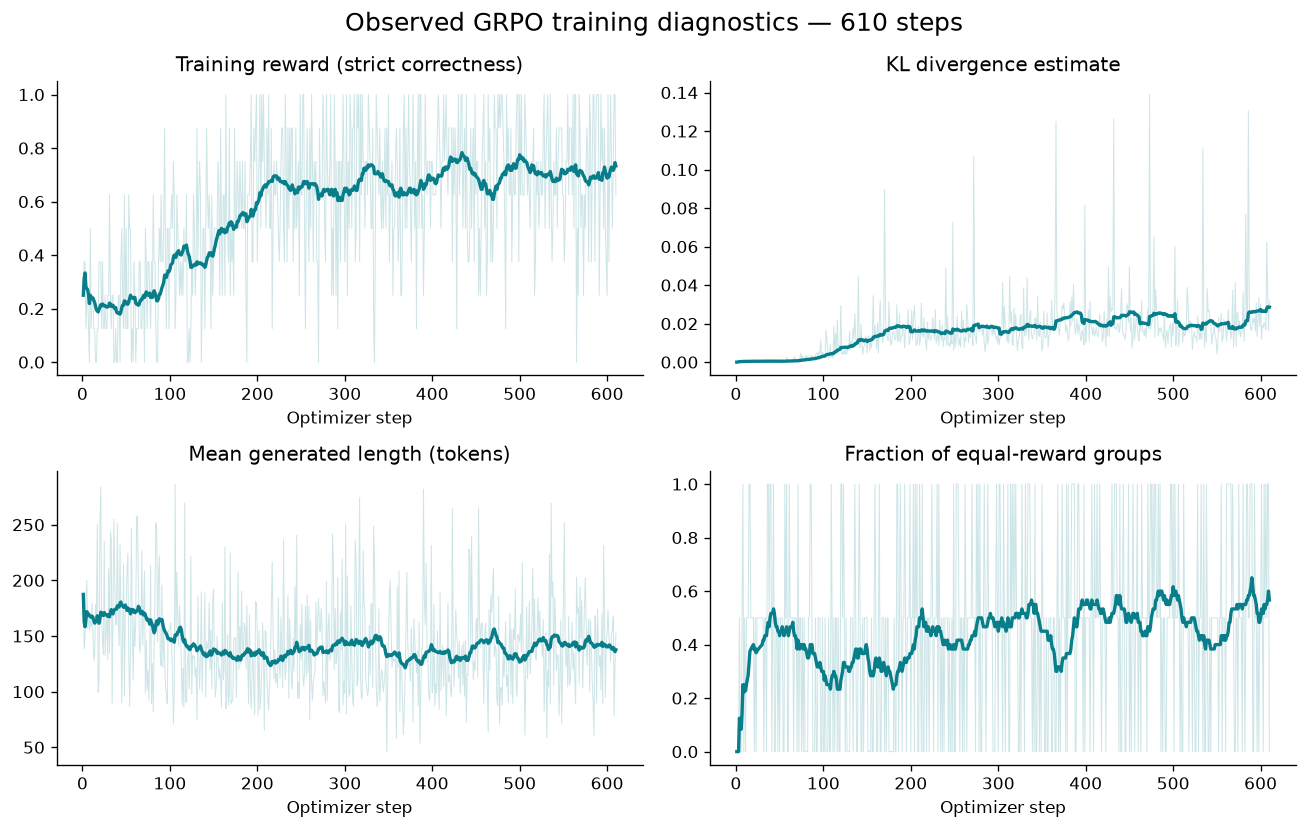

First 50-step mean reward: 0.218
Last 50-step mean reward:  0.7


In [6]:
steps = np.array([r['step'] for r in history])
def smooth(values, window=30):
    return np.array([np.mean(values[max(0,i-window+1):i+1]) for i in range(len(values))])
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, key, title in zip(axes.flat,
        ['reward', 'kl', 'completions/mean_length', 'frac_reward_zero_std'],
        ['Training reward (strict correctness)', 'KL divergence estimate',
         'Mean generated length (tokens)', 'Fraction of equal-reward groups']):
    values = np.array([r[key] for r in history])
    ax.plot(steps, values, color=COLORS[1], alpha=.2, linewidth=.6)
    ax.plot(steps, smooth(values), color=COLORS[1], linewidth=2)
    ax.set(title=title, xlabel='Optimizer step')
fig.suptitle('Observed GRPO training diagnostics — 610 steps', fontsize=15)
fig.tight_layout()
save_figure('01_training')
print('First 50-step mean reward:', round(np.mean([r['reward'] for r in history[:50]]), 3))
print('Last 50-step mean reward: ', round(np.mean([r['reward'] for r in history[-50:]]), 3))

## 5. Reproduce the held-out results

Evaluation uses one greedy response per question, the same prompt and a 512-token response limit.
Strict accuracy counts wrong-format answers as incorrect. Format compliance is displayed separately.
Validation and test questions were not used for gradient updates. The launcher evaluated the test
split before and after this fixed run; these results should not subsequently become tuning targets.

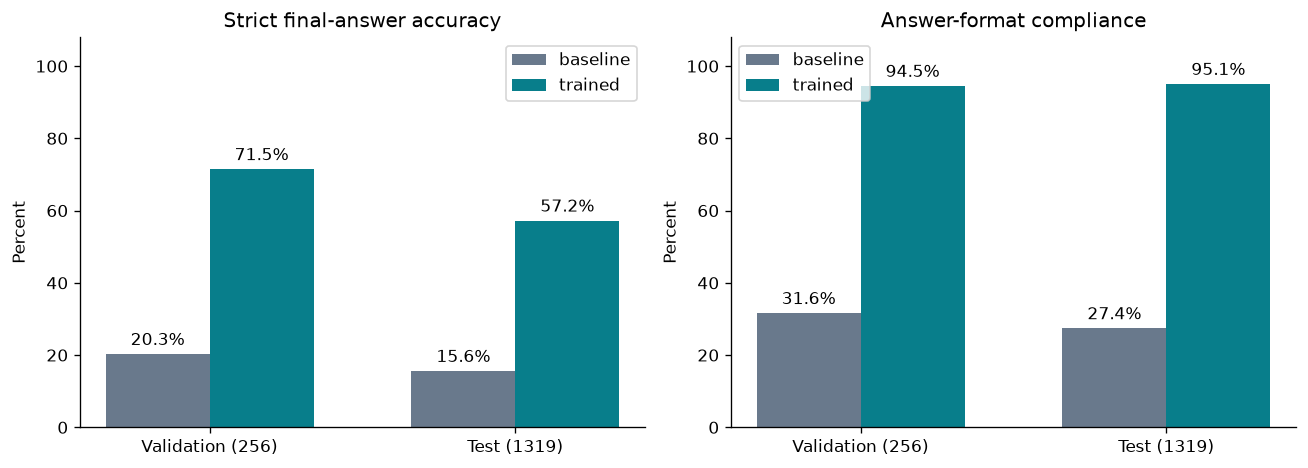

validation: 52/256 -> 183/256; delta=+51.17 pp
test: 206/1319 -> 755/1319; delta=+41.62 pp


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
x = np.arange(2)
for ax, metric, title in zip(axes, ['accuracy', 'format_rate'], ['Strict final-answer accuracy', 'Answer-format compliance']):
    for j, label in enumerate(['baseline', 'trained']):
        vals = [100 * read_json(f'{label}-{s}.json')[metric] for s in ['validation','test']]
        bars = ax.bar(x + (j-.5)*.34, vals, width=.34, label=label, color=COLORS[j])
        ax.bar_label(bars, fmt='%.1f%%', padding=3)
    ax.set(xticks=x, xticklabels=['Validation (256)', 'Test (1319)'], ylim=(0,108), ylabel='Percent', title=title)
    ax.legend()
fig.tight_layout()
save_figure('02_before_after')
for split in pairs:
    b, a = [read_json(f'{label}-{split}.json') for label in ['baseline','trained']]
    print(f"{split}: {b['correct']}/{b['n']} -> {a['correct']}/{a['n']}; delta={100*(a['accuracy']-b['accuracy']):+.2f} pp")

## 6. How much is answer formatting affecting the result?

The baseline sometimes gives a correct number inside a LaTeX box, which strict scoring rejects.
We apply a conservative **diagnostic rescoring** to the same saved responses: accept the original
strict answer, or a single distinct numeric value inside `\boxed{...}`. Repeated identical boxes
are accepted; conflicting numeric boxes are rejected. No last-number guessing or generated code execution is used.

This does not recognize all natural-language answers. Unrecognized responses remain incorrect,
so these are diagnostic recognized-answer rates, not a complete format-independent math benchmark.
The rule is applied symmetrically to both models and was designed after seeing this run.
It is useful evidence about the scoring confound, not a preregistered primary result.

validation strict: [np.float64(20.31), np.float64(71.48)] diagnostic: [np.float64(28.91), np.float64(72.27)]
test strict: [np.float64(15.62), np.float64(57.24)] diagnostic: [np.float64(26.08), np.float64(57.62)]


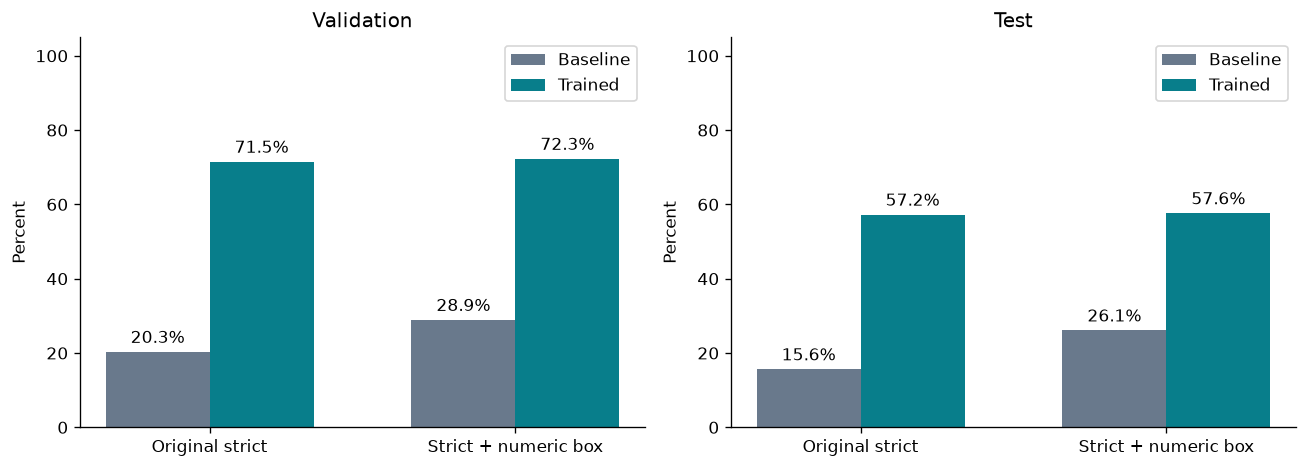

In [8]:
BOX = re.compile(r'\\boxed\{\s*\$?\s*([+-]?(?:\d{1,3}(?:,\d{3})+|\d+)(?:\.\d+)?)\s*\}')
def diagnostic_answer(text):
    strict = extract_answer(text)
    if strict is not None:
        return strict
    values = {Decimal(v.replace(',', '')) for v in BOX.findall(text)}
    return next(iter(values)) if len(values) == 1 else None
def diagnostic_correct(row):
    value = diagnostic_answer(row['completion'])
    return value is not None and value == Decimal(row['gold'])
assert diagnostic_answer(r'Final: \boxed{18}') == Decimal('18')
assert diagnostic_answer(r'\boxed{18} or \boxed{19}') is None
diagnostic = {}
for split, rows in pairs.items():
    diagnostic[split] = [np.mean([diagnostic_correct(p[j]) for p in rows]) for j in [0,1]]
    print(split, 'strict:', [round(100*np.mean([p[j]['correct'] for p in rows]),2) for j in [0,1]],
          'diagnostic:', [round(100*v,2) for v in diagnostic[split]])
fig, axes = plt.subplots(1,2,figsize=(11,4))
for ax, split in zip(axes, pairs):
    for j, label in enumerate(['Baseline','Trained']):
        vals = [100*np.mean([p[j]['correct'] for p in pairs[split]]), 100*diagnostic[split][j]]
        bars = ax.bar(np.arange(2)+(j-.5)*.34, vals, .34, label=label, color=COLORS[j])
        ax.bar_label(bars, fmt='%.1f%%', padding=3)
    ax.set(xticks=[0,1], xticklabels=['Original strict','Strict + numeric box'],
           ylim=(0,105), ylabel='Percent', title=split.title())
    ax.legend()
fig.tight_layout()
save_figure('03_format_sensitivity')

## 7. Paired evidence and uncertainty

Both models answer the same questions, so examine transitions (wrong→correct and correct→wrong),
rather than treating them as independent samples. A paired bootstrap resamples question IDs and
estimates uncertainty in the accuracy difference. These intervals reflect question sampling only:
one training seed, benchmark contamination, parser choices, and training variability are not covered.

In [9]:
rng = np.random.default_rng(42)
inference = {}
for split, rows in pairs.items():
    b = np.array([p[0]['correct'] for p in rows], dtype=int)
    a = np.array([p[1]['correct'] for p in rows], dtype=int)
    delta = a-b
    draws = np.array([rng.choice(delta, len(delta), replace=True).mean() for _ in range(10000)])
    low, high = 100*np.quantile(draws,[.025,.975])
    transitions = {'both_correct': int(((b==1)&(a==1)).sum()),
                   'improved': int(((b==0)&(a==1)).sum()),
                   'regressed': int(((b==1)&(a==0)).sum()),
                   'both_incorrect': int(((b==0)&(a==0)).sum())}
    inference[split] = {'strict_delta_pp': float(100*delta.mean()),
                        'paired_bootstrap_95_interval_pp': [float(low),float(high)], **transitions,
                        'diagnostic_before': diagnostic[split][0], 'diagnostic_after': diagnostic[split][1]}
    print(f'{split}: change {100*delta.mean():+.2f} pp; paired bootstrap 95% interval [{low:+.2f}, {high:+.2f}] pp')
    print(transitions)
(ROOT/'analysis_metrics.json').write_text(json.dumps(inference,indent=2))

validation: change +51.17 pp; paired bootstrap 95% interval [+44.14, +57.81] pp
{'both_correct': 44, 'improved': 139, 'regressed': 8, 'both_incorrect': 65}
test: change +41.62 pp; paired bootstrap 95% interval [+38.67, +44.51] pp
{'both_correct': 174, 'improved': 581, 'regressed': 32, 'both_incorrect': 532}


638

## 8. Inspect concrete answers

The following deterministic selections show a baseline answer rescued by diagnostic scoring,
a response that improves even under diagnostic scoring, and a strict regression (if present).
Examples are illustrative, selected by category and then dataset order; they are not a random audit.

In [10]:
categories = [
 ('Correct baseline number rejected by strict format', lambda b,a: not b['correct'] and diagnostic_correct(b)),
 ('Improvement under the diagnostic rule', lambda b,a: not diagnostic_correct(b) and diagnostic_correct(a)),
 ('Regression under strict scoring', lambda b,a: b['correct'] and not a['correct'])]
for title, predicate in categories:
    selected = next(((b,a) for b,a in pairs['test'] if predicate(b,a)), None)
    if selected is None:
        continue
    b,a = selected
    display(Markdown(chr(10).join([f"### {title} — test ID {b['id']}", '', b['question'], '', f"**Gold:** {b['gold']}"])))
    for label,row in [('Baseline',b),('Trained',a)]:
        print(f"{label}: strict={row['correct']}, diagnostic={diagnostic_correct(row)}")
        print(row['completion'])
        print()

### Correct baseline number rejected by strict format — test ID 0

Janet’s ducks lay 16 eggs per day. She eats three for breakfast every morning and bakes muffins for her friends every day with four. She sells the remainder at the farmers' market daily for $2 per fresh duck egg. How much in dollars does she make every day at the farmers' market?

**Gold:** 18

Baseline: strict=False, diagnostic=True
To determine how much Janet makes from selling the eggs at the farmers' market each day, we need to follow these steps:

1. Calculate the total number of eggs laid by the ducks per day.
2. Determine how many eggs are eaten for breakfast.
3. Subtract the eggs eaten for breakfast from the total to find out how many eggs are left for baking muffins.
4. Subtract the eggs used for baking muffins from the remaining eggs to find out how many eggs are sold at the farmers' market.
5. Calculate the revenue from selling the eggs.

Let's go through these steps in detail:

1. The ducks lay 16 eggs per day.
2. Janet eats 3 eggs for breakfast every morning:
   \[
   16 - 3 = 13 \text{ eggs}
   \]
3. She uses 4 eggs to bake muffins:
   \[
   13 - 4 = 9 \text{ eggs}
   \]
4. The remaining eggs that are sold at the farmers' market are:
   \[
   9 \text{ eggs}
   \]

Now, let's calculate the revenue from selling these eggs at $2 per egg:
\[
9 \times 2 = \$18
\]

Th

### Improvement under the diagnostic rule — test ID 5

Kylar went to the store to buy glasses for his new apartment. One glass costs $5, but every second glass costs only 60% of the price. Kylar wants to buy 16 glasses. How much does he need to pay for them?

**Gold:** 64

Baseline: strict=False, diagnostic=False
To calculate how much Kylar needs to pay for 16 glasses:

- The first glass costs $5.
- Each subsequent glass costs 60% of the original price.

First glass cost: $5

Second glass cost: \( 5 \times 0.6 = \$3 \)

Third glass cost: \( 5 \times 0.6 = \$3 \)

...

Sixteenth glass cost: \( 5 \times 0.6 = \$3 \)

Total cost for 16 glasses:
\( 16 \times 5 + (16 - 1) \times 3 \)
\( = 80 + 15 \times 3 \)
\( = 80 + 45 \)
\( = \$125 \)

#### 125

Trained: strict=True, diagnostic=True
The first 8 glasses cost \(8 \times \$5 = \$40\).

The remaining 8 glasses cost \(8 \times (60\% \times \$5) = 8 \times 0.6 \times \$5 = \$24\).

So, the total amount Kylar needs to pay is \( \$40 + \$24 = \$64 \).

#### 64



### Regression under strict scoring — test ID 77

If Raymond does half as much laundry as Sarah, and Sarah does 4 times as much laundry as David, calculate the difference in the amount of laundry Raymond and David do if Sarah does 400 pounds of laundry.

**Gold:** 100

Baseline: strict=True, diagnostic=True
To find out how much laundry each person does:

1. First, we know that Sarah does 400 pounds of laundry.
2. Since Sarah does 4 times as much laundry as David, we can calculate how much David does:
   \[
   \text{David's laundry} = \frac{\text{Sarah's laundry}}{4} = \frac{400}{4} = 100 \text{ pounds}
   \]
3. Raymond does half as much laundry as Sarah, so:
   \[
   \text{Raymond's laundry} = \frac{\text{Sarah's laundry}}{2} = \frac{400}{2} = 200 \text{ pounds}
   \]

Now, to find the difference between the amount of laundry done by Raymond and David:
\[
\text{Difference} = \text{Raymond's laundry} - \text{David's laundry} = 200 - 100 = 100 \text{ pounds}
\]

#### 100

Trained: strict=False, diagnostic=False
First find how much laundry David does: 400 pounds / 4 = 100 pounds
Then find how much laundry Raymond does: 100 pounds * 0.5 = 50 pounds

The difference between what Raymond and David do is: 100 - 50 = 50 pounds

#### 50



## 9. What can we conclude?

- This run improved the predefined strict scoring objective on the held-out test split.
- Format compliance improved substantially; the reported strict gain combines formatting and
  numeric-answer changes. Use the diagnostic comparison and examples when discussing mathematical improvement.
- Reward curves describe sampled training behavior, not held-out learning curves. There are only
  two held-out measurement points (before and after).
- One run cannot establish repeatability. Public GSM8K may overlap with the base model's pretraining;
  new independently written problems would improve the generalization assessment.
- Correct final answers do not verify intermediate reasoning. Truncation and the 512-token budget
  may also affect results. Performance may change under a different prompt or decoding scheme.

**Next experiment:** define a format-tolerant scoring protocol before running, manually audit a
random sample of parsed answers, use multiple training seeds, and compare GRPO with a simpler
format-only supervised baseline. Keep the official test set out of further tuning decisions.

**Suggested presentation wording:** “We fine-tuned Qwen2.5-1.5B-Instruct with GRPO and LoRA for
approximately three hours. Strict GSM8K test accuracy increased from 15.62% to 57.24%. Because
answer formatting is part of our reward and evaluation rule, we also analyzed formatting and
rescored explicit numeric boxes. We interpret the outcome as improved task performance under
this protocol, with further controls needed to isolate mathematical reasoning gains.”

## References and provenance

- [Versioned TRL GRPO documentation](https://huggingface.co/docs/trl/v0.23.1/en/grpo_trainer)
- [Qwen model card](https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct)
- [GSM8K dataset](https://huggingface.co/datasets/openai/gsm8k)
- Empirical source: user-supplied `grpo-results.zip`, run `20261030-070033-233345`.
- `source/` contains the archived scripts; `results/` contains the selected original logs and predictions.
  No adapter weights are included. PNG and PDF figures are exported into `figures/`.